In [1]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.naive_bayes import CategoricalNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    mutual_info_score
)

from preprocessing import load_adult, to_categories

In [2]:
#loading the dataset
trainDf, testDf = load_adult()
print(trainDf.shape)
print(testDf.shape)
trainDf.head()

(32561, 15)
(16281, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


In [3]:
#seperating features and labels
xTrain = trainDf.drop(columns=["income"])
yTrain = trainDf["income"]

xTest = testDf.drop(columns=["income"])
yTest = testDf["income"]

In [4]:
#preprocessing features
xTrainCat, xTestCat = to_categories(trainDf, testDf)

print(xTrainCat.shape)
print(xTestCat.shape)
xTrainCat.head()

(32561, 14)
(16281, 14)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,3,6,0,9,8,4,0,1,4,1,6,0,3,38
1,4,5,0,9,8,2,3,0,4,1,0,0,1,38
2,2,3,1,11,5,0,5,1,4,1,0,0,3,38
3,4,3,1,1,4,2,5,0,2,1,0,0,3,38
4,1,3,2,9,8,2,9,5,2,0,0,0,3,4


In [5]:
#checking min & max
for col in xTrainCat.columns:
    print(col, xTrainCat[col].min(), xTestCat[col].min(),
          xTrainCat[col].max(), xTestCat[col].max())

age 0 0 9 9
workclass 0 0 8 8
fnlwgt 0 0 9 9
education 0 0 15 15
education-num 0 0 9 9
marital-status 0 0 6 6
occupation 0 0 14 14
relationship 0 0 5 5
race 0 0 4 4
sex 0 0 1 1
capital-gain 0 0 9 9
capital-loss 0 0 9 9
hours-per-week 0 0 9 9
native-country 0 0 41 41


In [6]:
#training initial Naive Bayes model
nbModel = CategoricalNB()
nbModel.fit(xTrainCat, yTrain)

CategoricalNB()

In [7]:
#evaluating initial model
yPred = nbModel.predict(xTestCat)

initialAccuracy = accuracy_score(yTest, yPred)

print("Naive Bayes Accuracy:", initialAccuracy)
print(classification_report(yTest, yPred))
print(confusion_matrix(yTest, yPred))

Naive Bayes Accuracy: 0.8251335913027456
              precision    recall  f1-score   support

           0       0.92      0.84      0.88     12435
           1       0.60      0.77      0.68      3846

    accuracy                           0.83     16281
   macro avg       0.76      0.81      0.78     16281
weighted avg       0.85      0.83      0.83     16281

[[10463  1972]
 [  875  2971]]


In [8]:
#setting up grid search and cross validation
paramGrid = {
    "alpha": [0.1, 0.5, 1.0, 2.0, 5.0]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [9]:
#running grid search
grid = GridSearchCV(
    CategoricalNB(),
    paramGrid,
    cv=cv,
    scoring="accuracy",
    return_train_score=True
)

grid.fit(xTrainCat, yTrain)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=CategoricalNB(),
             param_grid={'alpha': [0.1, 0.5, 1.0, 2.0, 5.0]},
             return_train_score=True, scoring='accuracy')

In [10]:
#grid search results
trainAcc = grid.cv_results_["mean_train_score"][grid.best_index_]
valAcc = grid.best_score_

print(f"Best alpha: {grid.best_params_['alpha']}")
print(f"Training accuracy: {trainAcc:.1%}")
print(f"Validation accuracy: {valAcc:.1%}")

Best alpha: 5.0
Training accuracy: 82.4%
Validation accuracy: 82.4%


In [11]:
#evaluating with grid and cross validation
yPredTuned = grid.predict(xTestCat)
testAcc = accuracy_score(yTest, yPredTuned)

print(f"Tuned Naive Bayes Test Accuracy: {testAcc:.1%}")

Tuned Naive Bayes Test Accuracy: 82.6%


In [12]:
#model result summary
results = pd.DataFrame({
    "Metric": [
        "Initial Test Accuracy",
        "Best Alpha",
        "Training Accuracy",
        "Cross-Validation Accuracy",
        "Tuned Test Accuracy"
    ],
    "Result": [
        f"{initialAccuracy:.2%}",
        grid.best_params_["alpha"],
        f"{trainAcc:.2%}",
        f"{valAcc:.2%}",
        f"{testAcc:.2%}"
    ]
})

display(results)

,Metric,Result
0,Initial Test Accuracy,82.51%
1,Best Alpha,5.0
2,Training Accuracy,82.43%
3,Cross-Validation Accuracy,82.39%
4,Tuned Test Accuracy,82.60%


In [13]:
#function to introduce label noise
def addLabelNoise(y, noiseLevel, randomState=42):
    rng = np.random.default_rng(randomState)
    yNoisy = y.copy().to_numpy()

    nFlip = int(len(yNoisy) * noiseLevel)
    flipIndices = rng.choice(len(yNoisy), size=nFlip, replace=False)

    yNoisy[flipIndices] = 1 - yNoisy[flipIndices]

    return yNoisy

In [14]:
#repeat noise experiments with different random seeds
noiseLevels = [0, 0.1, 0.2, 0.3, 0.4]
seeds = [0, 1, 2, 3, 4]
repeatResults = []

for seed in seeds:
    for noiseLevel in noiseLevels:
        yTrainNoisy = addLabelNoise(
            yTrain, noiseLevel, randomState=seed
        )

        model = CategoricalNB(alpha=grid.best_params_["alpha"])
        model.fit(xTrainCat, yTrainNoisy)

        yPred = model.predict(xTestCat)
        errorRate = 1 - accuracy_score(yTest, yPred)

        repeatResults.append({
            "Seed": seed,
            "Noise Level": noiseLevel,
            "Error Rate": errorRate
        })

repeatDf = pd.DataFrame(repeatResults)

#average error across the five runs
summaryDf = repeatDf.groupby("Noise Level")["Error Rate"].agg(
    ["mean", "std"]
)

display(summaryDf)

,mean,std
Noise Level,,
0.0,0.174007,0.000000
0.1,0.189620,0.000950
0.2,0.198550,0.001044
0.3,0.205405,0.001366
0.4,0.211989,0.003491


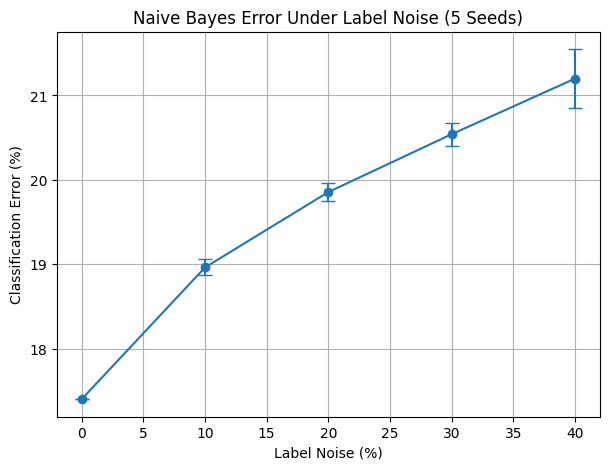

In [15]:
#plot average classification error with standard deviation
plt.figure(figsize=(7, 5))

plt.errorbar(
    summaryDf.index * 100,
    summaryDf["mean"] * 100,
    yerr=summaryDf["std"] * 100,
    marker="o",
    capsize=5
)

plt.xlabel("Label Noise (%)")
plt.ylabel("Classification Error (%)")
plt.title("Naive Bayes Error Under Label Noise (5 Seeds)")
plt.grid(True)
plt.show()

In [16]:
#combine two features
features = trainDf[["education", "marital-status"]]
jointFeature = features.astype(str).agg("_".join, axis=1)

#calculate mutual information with income
trueMI = mutual_info_score(jointFeature, yTrain)

print("Mutual Information:", trueMI)

Mutual Information: 0.17086365204782122


In [17]:
#probabilities under the Naive Bayes assumption
labels = pd.Series(np.asarray(yTrain))

feature1 = features["education"].reset_index(drop=True)
feature2 = features["marital-status"].reset_index(drop=True)

classProbs = labels.value_counts(normalize=True).sort_index()

educationProbs = pd.crosstab(
    labels, feature1, normalize="index"
)

maritalProbs = pd.crosstab(
    labels, feature2, normalize="index"
)

print("Class probabilities:")
print(classProbs)

print("Education probabilities:", educationProbs.shape)
print("Marital status probabilities:", maritalProbs.shape)

Class probabilities:
0    0.75919
1    0.24081
Name: proportion, dtype: float64
Education probabilities: (2, 16)
Marital status probabilities: (2, 7)


In [18]:
#calculate mutual information under Naive Bayes
pC = classProbs.to_numpy()
pE = educationProbs.to_numpy()
pM = maritalProbs.to_numpy()

#joint distribution under conditional independence
pJoint = pC[:, None, None] * pE[:, :, None] * pM[:, None, :]

#probability of each feature combination
pFeatures = pJoint.sum(axis=0)

#calculate Naive Bayes mutual information
denominator = pC[:, None, None] * pFeatures[None, :, :]

mask = pJoint > 0

nbMI = np.sum(
    pJoint[mask] * np.log(pJoint[mask] / denominator[mask])
)

#information loss
infoLoss = trueMI - nbMI

print("True Mutual Information:", trueMI)
print("Naive Bayes Mutual Information:", nbMI)
print("Information Loss:", infoLoss)

True Mutual Information: 0.17086365204782122
Naive Bayes Mutual Information: 0.15959156395237103
Information Loss: 0.011272088095450189


In [19]:
#calculate information loss for a given set of labels
def calculateInfoLoss(y):
    labels = pd.Series(np.asarray(y))
    jointFeature = features.astype(str).agg("_".join, axis=1)

    trueMI = mutual_info_score(jointFeature, labels)

    classProbs = labels.value_counts(normalize=True).sort_index()

    educationProbs = pd.crosstab(
        labels, features["education"].reset_index(drop=True),
        normalize="index"
    )

    maritalProbs = pd.crosstab(
        labels, features["marital-status"].reset_index(drop=True),
        normalize="index"
    )

    pC = classProbs.to_numpy()
    pE = educationProbs.to_numpy()
    pM = maritalProbs.to_numpy()

    pJoint = pC[:, None, None] * pE[:, :, None] * pM[:, None, :]
    pFeatures = pJoint.sum(axis=0)

    denominator = pC[:, None, None] * pFeatures[None, :, :]
    mask = pJoint > 0

    nbMI = np.sum(
        pJoint[mask] * np.log(pJoint[mask] / denominator[mask])
    )

    return trueMI - nbMI

In [20]:
#repeat information loss experiments with different seeds
infoRepeatResults = []

for seed in seeds:
    for noiseLevel in noiseLevels:
        yTrainNoisy = addLabelNoise(
            yTrain, noiseLevel, randomState=seed
        )

        infoLoss = calculateInfoLoss(yTrainNoisy)

        infoRepeatResults.append({
            "Seed": seed,
            "Noise Level": noiseLevel,
            "Information Loss": infoLoss
        })

infoRepeatDf = pd.DataFrame(infoRepeatResults)

infoSummaryDf = infoRepeatDf.groupby("Noise Level")[
    "Information Loss"
].agg(["mean", "std"])

display(infoSummaryDf)

,mean,std
Noise Level,,
0.0,0.011272,0.000000
0.1,0.001739,0.000501
0.2,0.000834,0.000578
0.3,0.000898,0.000343
0.4,0.001273,0.000145


In [21]:
#prepare the same two features for Naive Bayes
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

xTrainTwo = encoder.fit_transform(
    trainDf[["education", "marital-status"]]
)

xTestTwo = encoder.transform(
    testDf[["education", "marital-status"]]
)

#shift values so all categories are nonnegative
xTrainTwo = xTrainTwo.astype(int) + 1
xTestTwo = xTestTwo.astype(int) + 1

print(xTrainTwo.shape)
print(xTestTwo.shape)

(32561, 2)
(16281, 2)


In [22]:
#repeat two-feature experiments with different seeds
twoFeatureRepeatResults = []

for seed in seeds:
    for noiseLevel in noiseLevels:
        yTrainNoisy = addLabelNoise(
            yTrain, noiseLevel, randomState=seed
        )

        model = CategoricalNB(alpha=grid.best_params_["alpha"])
        model.fit(xTrainTwo, yTrainNoisy)

        yPred = model.predict(xTestTwo)
        errorRate = 1 - accuracy_score(yTest, yPred)

        twoFeatureRepeatResults.append({
            "Seed": seed,
            "Noise Level": noiseLevel,
            "Error Rate": errorRate
        })

twoFeatureRepeatDf = pd.DataFrame(twoFeatureRepeatResults)

twoFeatureSummaryDf = twoFeatureRepeatDf.groupby("Noise Level")[
    "Error Rate"
].agg(["mean", "std"])

display(twoFeatureSummaryDf)

,mean,std
Noise Level,,
0.0,0.177753,0.000000
0.1,0.177090,0.000227
0.2,0.177434,0.000296
0.3,0.177716,0.000120
0.4,0.181181,0.002727


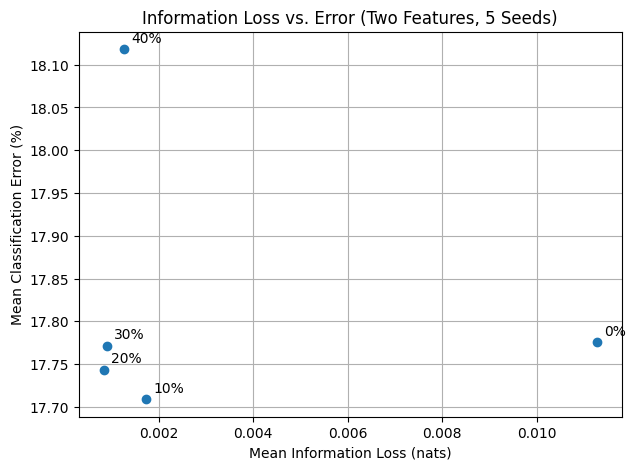

In [23]:
#compare average information loss and error
comparisonSummaryDf = pd.DataFrame({
    "Information Loss": infoSummaryDf["mean"],
    "Error Rate": twoFeatureSummaryDf["mean"]
})

plt.figure(figsize=(7, 5))

plt.scatter(
    comparisonSummaryDf["Information Loss"],
    comparisonSummaryDf["Error Rate"] * 100
)

for noiseLevel, row in comparisonSummaryDf.iterrows():
    plt.annotate(
        f"{noiseLevel * 100:.0f}%",
        (row["Information Loss"], row["Error Rate"] * 100),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Mean Information Loss (nats)")
plt.ylabel("Mean Classification Error (%)")
plt.title("Information Loss vs. Error (Two Features, 5 Seeds)")
plt.grid(True)
plt.show()

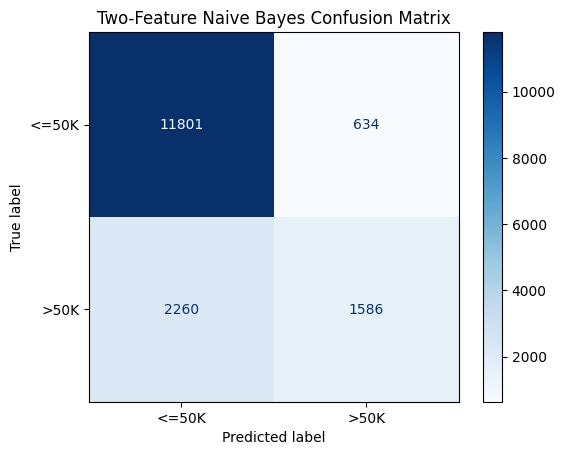

              precision    recall  f1-score   support

       <=50K       0.84      0.95      0.89     12435
        >50K       0.71      0.41      0.52      3846

    accuracy                           0.82     16281
   macro avg       0.78      0.68      0.71     16281
weighted avg       0.81      0.82      0.80     16281



In [24]:
#train two-feature model without label noise
model = CategoricalNB(alpha=grid.best_params_["alpha"])
model.fit(xTrainTwo, yTrain)

#predict on clean test data
yPred = model.predict(xTestTwo)

#display confusion matrix
cm = confusion_matrix(yTest, yPred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["<=50K", ">50K"]
).plot(cmap="Blues")

plt.title("Two-Feature Naive Bayes Confusion Matrix")
plt.show()

#classification report for two-feature model
print(classification_report(
    yTest,
    yPred,
    target_names=["<=50K", ">50K"]
))

In [26]:
#precision and recall under label noise (5 seeds)
metricResults = []

for seed in seeds:
    for noiseLevel in noiseLevels:
        yTrainNoisy = addLabelNoise(
            yTrain, noiseLevel, randomState=seed
        )

        model = CategoricalNB(alpha=grid.best_params_["alpha"])
        model.fit(xTrainTwo, yTrainNoisy)

        yPred = model.predict(xTestTwo)

        metricResults.append({
            "Seed": seed,
            "Noise Level": noiseLevel,
            "Precision >50K": precision_score(yTest, yPred, zero_division=0),
            "Recall >50K": recall_score(yTest, yPred, zero_division=0)
        })

metricDf = pd.DataFrame(metricResults)

metricSummaryDf = metricDf.groupby("Noise Level")[
    ["Precision >50K", "Recall >50K"]
].agg(["mean", "std"])

display(metricSummaryDf)

Precision >50K           Recall >50K          
                      mean       std        mean       std
Noise Level                                               
0.0               0.714414  0.000000    0.412376  0.000000
0.1               0.713576  0.000403    0.418201  0.001577
0.2               0.710360  0.003804    0.420281  0.003748
0.3               0.708464  0.002181    0.420905  0.003144
0.4               0.682811  0.022122    0.437441  0.018023